In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
os.makedirs('Visualisations', exist_ok=True)

# Load Week 3 healthcare datasets
encounters = pd.read_csv('encounters.csv')
patients = pd.read_csv('patients.csv')
procedures = pd.read_csv('procedures.csv')
payers = pd.read_csv('payers.csv')
organizations = pd.read_csv('organizations.csv')

# Drop patient PII immediately to uphold privacy standards
pii_cols = [c for c in ['FIRST', 'LAST', 'ADDRESS', 'SSN', 'DRIVERS', 'PASSPORT'] if c in patients.columns]
patients = patients.drop(columns=pii_cols)

tables = {
    'encounters': encounters,
    'patients': patients,
    'procedures': procedures,
    'payers': payers,
    'organizations': organizations
}

for name, df in tables.items():
    print(f"=== {name.upper()} ===")
    print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print(f"Columns: {list(df.columns)}")
    print(f"Exact Duplicates: {df.duplicated().sum()}")
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    print("Missing Values:\n" + (missing.to_string() if not missing.empty else "None"))
    print("-" * 55)

=== ENCOUNTERS ===
Shape: 27,891 rows x 14 columns
Columns: ['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']
Exact Duplicates: 0
Missing Values:
REASONCODE           19541
REASONDESCRIPTION    19541
-------------------------------------------------------
=== PATIENTS ===
Shape: 974 rows x 17 columns
Columns: ['Id', 'BIRTHDATE', 'DEATHDATE', 'PREFIX', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON']
Exact Duplicates: 0
Missing Values:
DEATHDATE    820
SUFFIX       953
MAIDEN       588
MARITAL        1
ZIP          142
-------------------------------------------------------
=== PROCEDURES ===
Shape: 47,701 rows x 9 columns
Columns: ['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'BASE_COST', 'REASONCODE', 'REASONDESCRIPTION']
Exact Duplicates: 0
Missin

In [2]:
# Parse ISO timestamps
encounters['START'] = pd.to_datetime(encounters['START'], errors='coerce')
encounters['STOP'] = pd.to_datetime(encounters['STOP'], errors='coerce')

# Calculate encounter duration in hours (flagging invalid/negative durations)
encounters['duration_hours'] = (encounters['STOP'] - encounters['START']).dt.total_seconds() / 3600.0
invalid_dur = (encounters['duration_hours'] < 0).sum()
print(f"Encounters Date Range: {encounters['START'].min()} to {encounters['START'].max()}")
print(f"Negative/Invalid Durations Flagged: {invalid_dur}")

# Merge payer names and procedure counts onto encounters
enc_merged = encounters.merge(
    payers[['Id', 'NAME']].rename(columns={'Id': 'PAYER', 'NAME': 'payer_name'}),
    on='PAYER',
    how='left'
)

proc_counts = procedures.groupby('ENCOUNTER').size().reset_index(name='procedure_count')
enc_merged = enc_merged.merge(proc_counts, left_on='Id', right_on='ENCOUNTER', how='left')
enc_merged['procedure_count'] = enc_merged['procedure_count'].fillna(0).astype(int)

# Check if cost columns exist in encounters.csv
cost_cols = [c for c in ['BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE'] if c in enc_merged.columns]
print(f"Cost columns detected in encounters.csv: {cost_cols}")

if 'TOTAL_CLAIM_COST' in enc_merged.columns and 'PAYER_COVERAGE' in enc_merged.columns:
    enc_merged['out_of_pocket_gap'] = enc_merged['TOTAL_CLAIM_COST'] - enc_merged['PAYER_COVERAGE']
    enc_merged['coverage_ratio_%'] = np.where(
        enc_merged['TOTAL_CLAIM_COST'] > 0,
        (enc_merged['PAYER_COVERAGE'] / enc_merged['TOTAL_CLAIM_COST']) * 100,
        np.nan
    )

Encounters Date Range: 2011-01-02 09:26:36+00:00 to 2022-02-05 20:27:36+00:00
Negative/Invalid Durations Flagged: 0
Cost columns detected in encounters.csv: ['BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE']


In [3]:
# Choose active cost metric (TOTAL_CLAIM_COST if available, else duration_hours)
target_col = 'TOTAL_CLAIM_COST' if 'TOTAL_CLAIM_COST' in enc_merged.columns else 'duration_hours'
print(f"Primary Metric for Group Comparisons: {target_col}\n")

print("=== 1. SUMMARY BY ENCOUNTER CLASS ===")
class_summary = enc_merged.groupby('ENCOUNTERCLASS').agg(
    encounters=('Id', 'count'),
    median_duration_hrs=('duration_hours', 'median'),
    mean_duration_hrs=('duration_hours', 'mean'),
    median_metric=(target_col, 'median'),
    mean_metric=(target_col, 'mean'),
    iqr_metric=(target_col, lambda x: x.quantile(0.75) - x.quantile(0.25))
).round(2).sort_values(by='encounters', ascending=False)
print(class_summary, "\n")

print("=== 2. SUMMARY BY PAYER ===")
payer_summary = enc_merged.groupby('payer_name').agg(
    encounters=('Id', 'count'),
    median_metric=(target_col, 'median'),
    mean_metric=(target_col, 'mean')
).round(2).sort_values(by='encounters', ascending=False)
if 'PAYER_COVERAGE' in enc_merged.columns:
    payer_cov = enc_merged.groupby('payer_name')['PAYER_COVERAGE'].agg(['median', 'mean']).round(2)
    payer_summary = payer_summary.join(payer_cov.rename(columns={'median': 'median_coverage', 'mean': 'mean_coverage'}))
print(payer_summary, "\n")

print("=== 3. TOP 10 PROCEDURES BY FREQUENCY ===")
top_procs = procedures.groupby('DESCRIPTION').agg(
    procedure_count=('CODE', 'count'),
    median_base_cost=('BASE_COST', 'median'),
    mean_base_cost=('BASE_COST', 'mean')
).round(2).sort_values(by='procedure_count', ascending=False).head(10)
print(top_procs)

Primary Metric for Group Comparisons: TOTAL_CLAIM_COST

=== 1. SUMMARY BY ENCOUNTER CLASS ===
                encounters  median_duration_hrs  mean_duration_hrs  median_metric  mean_metric  iqr_metric
ENCOUNTERCLASS                                                                                            
ambulatory           12537                 0.25               9.48         573.98      2894.11     1124.50
outpatient            6300                 0.25               5.88         278.58      2237.30      440.55
urgentcare            3666                 0.25               0.25         142.58      6369.16     8778.80
emergency             2322                 1.00               1.54         146.18      4629.65     4142.20
wellness              1931                 0.25               0.25        1231.44      4260.71      790.32
inpatient             1135                24.00              36.84        2355.59      7761.35    13778.30 

=== 2. SUMMARY BY PAYER ===
                    

In [5]:
valid_df = enc_merged[enc_merged['duration_hours'] >= 0].dropna(subset=[target_col]).copy()

print("=== HYPOTHESIS 1: METRIC DIFFERENCE ACROSS ENCOUNTER CLASSES (KRUSKAL-WALLIS) ===")
print(f"H0: Median {target_col} is equal across all ENCOUNTERCLASS categories.")
print(f"H1: At least one ENCOUNTERCLASS has a significantly different {target_col}.\n")
class_groups = [grp[target_col].values for _, grp in valid_df.groupby('ENCOUNTERCLASS') if len(grp) > 0]
h_class, p_class = stats.kruskal(*class_groups)
print(f"Kruskal-Wallis H = {h_class:.4f} | p-value = {p_class:.4e}\n")

print("=== HYPOTHESIS 2: ENCOUNTER DURATION VS. PRIMARY METRIC (SPEARMAN) ===")
print(f"H0: No monotonic correlation between duration_hours and {target_col}.")
print(f"H1: Significant monotonic correlation between duration_hours and {target_col}.\n")
rho_dur, p_dur = stats.spearmanr(valid_df['duration_hours'], valid_df[target_col])
print(f"Spearman rho = {rho_dur:.4f} | p-value = {p_dur:.4e}\n")

print("=== HYPOTHESIS 3: DIFFERENCE ACROSS INSURANCE PAYERS (KRUSKAL-WALLIS) ===")
payer_col = 'PAYER_COVERAGE' if 'PAYER_COVERAGE' in valid_df.columns else target_col
print(f"H0: Median {payer_col} does not differ across insurance payers.")
print(f"H1: Median {payer_col} differs significantly across at least one payer.\n")
payer_groups = [grp[payer_col].values for _, grp in valid_df.groupby('payer_name') if len(grp) > 0]
h_payer, p_payer = stats.kruskal(*payer_groups)
print(f"Kruskal-Wallis H = {h_payer:.4f} | p-value = {p_payer:.4e}")

=== HYPOTHESIS 1: METRIC DIFFERENCE ACROSS ENCOUNTER CLASSES (KRUSKAL-WALLIS) ===
H0: Median TOTAL_CLAIM_COST is equal across all ENCOUNTERCLASS categories.
H1: At least one ENCOUNTERCLASS has a significantly different TOTAL_CLAIM_COST.

Kruskal-Wallis H = 2025.1938 | p-value = 0.0000e+00

=== HYPOTHESIS 2: ENCOUNTER DURATION VS. PRIMARY METRIC (SPEARMAN) ===
H0: No monotonic correlation between duration_hours and TOTAL_CLAIM_COST.
H1: Significant monotonic correlation between duration_hours and TOTAL_CLAIM_COST.

Spearman rho = 0.3379 | p-value = 0.0000e+00

=== HYPOTHESIS 3: DIFFERENCE ACROSS INSURANCE PAYERS (KRUSKAL-WALLIS) ===
H0: Median PAYER_COVERAGE does not differ across insurance payers.
H1: Median PAYER_COVERAGE differs significantly across at least one payer.

Kruskal-Wallis H = 22239.0329 | p-value = 0.0000e+00


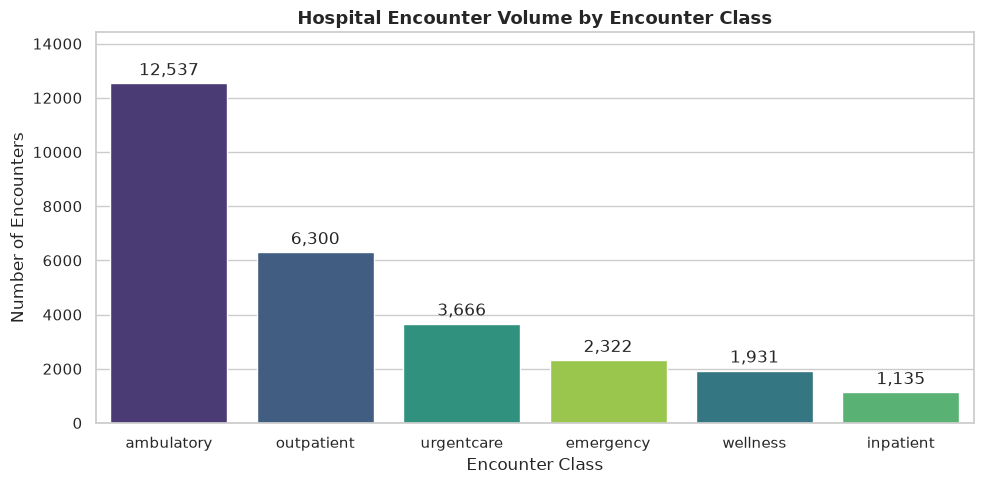

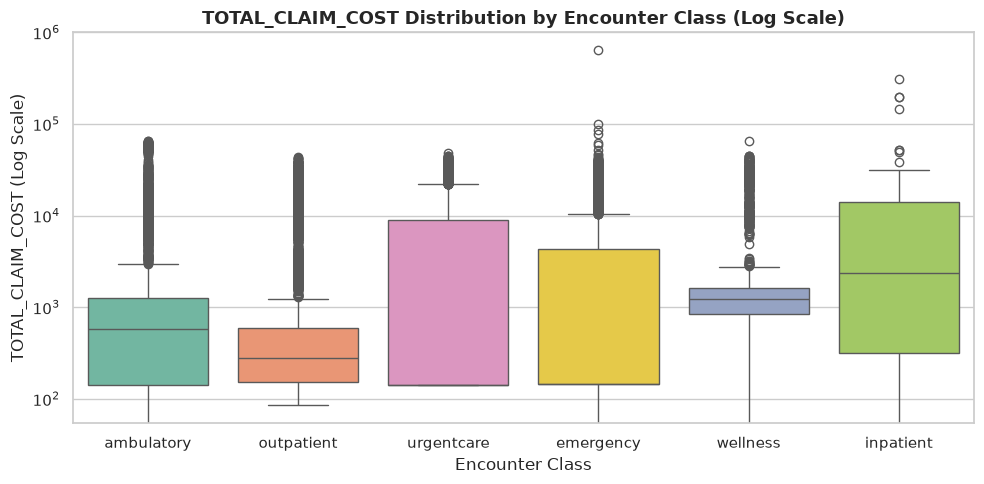

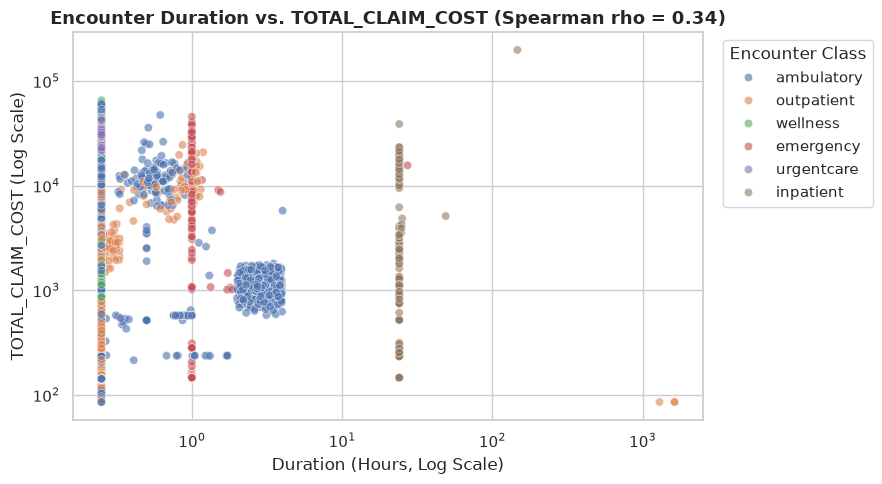

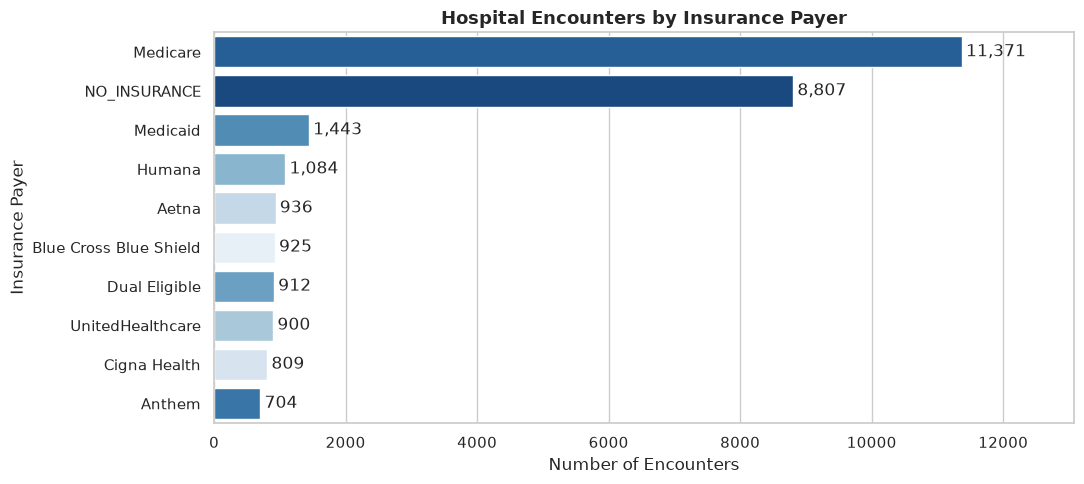

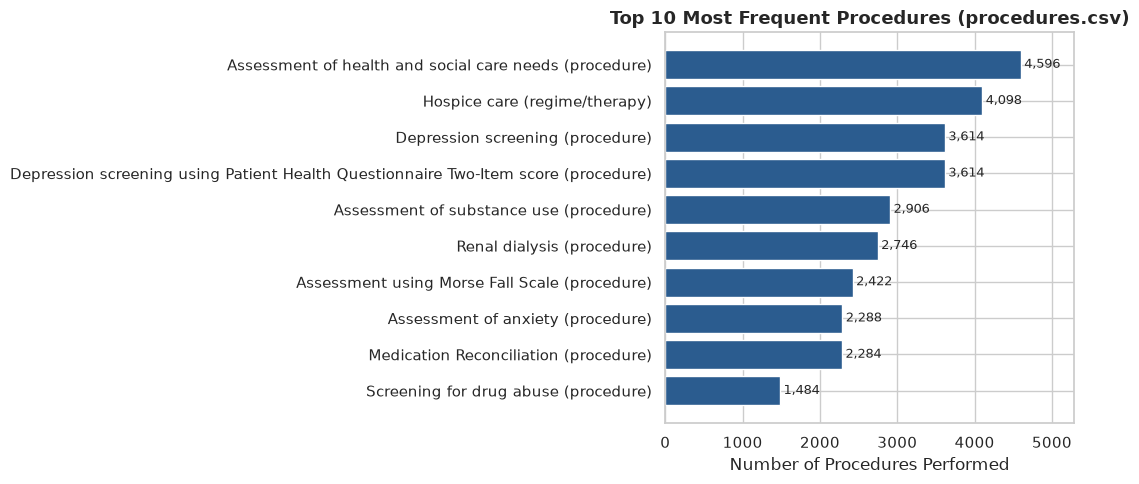

In [6]:
sns.set_theme(style="whitegrid")

# 1. Encounter Volume by Encounter Class
plt.figure(figsize=(10, 5))
order_cls = enc_merged['ENCOUNTERCLASS'].value_counts().index
ax = sns.countplot(data=enc_merged, x='ENCOUNTERCLASS', order=order_cls, hue='ENCOUNTERCLASS', palette='viridis', legend=False)
for c in ax.containers:
    ax.bar_label(c, fmt='{:,.0f}', padding=3)
plt.title('Hospital Encounter Volume by Encounter Class', fontsize=13, fontweight='bold')
plt.xlabel('Encounter Class')
plt.ylabel('Number of Encounters')
plt.ylim(0, enc_merged['ENCOUNTERCLASS'].value_counts().max() * 1.15)
plt.tight_layout()
plt.savefig('Visualisations/01_encounter_volume_by_class.png', dpi=300)
plt.show()

# 2. Primary Metric Distribution Across Encounter Classes (Log Scale for Skewness)
plt.figure(figsize=(10, 5))
sns.boxplot(data=valid_df, x='ENCOUNTERCLASS', y=target_col, order=order_cls, hue='ENCOUNTERCLASS', palette='Set2', legend=False)
plt.yscale('log')
plt.title(f'{target_col} Distribution by Encounter Class (Log Scale)', fontsize=13, fontweight='bold')
plt.xlabel('Encounter Class')
plt.ylabel(f'{target_col} (Log Scale)')
plt.tight_layout()
plt.savefig('Visualisations/02_metric_by_encounter_class.png', dpi=300)
plt.show()

# 3. Encounter Duration vs. Primary Metric
plt.figure(figsize=(9, 5))
sample_df = valid_df.sample(min(5000, len(valid_df)), random_state=42)
sns.scatterplot(data=sample_df, x='duration_hours', y=target_col, hue='ENCOUNTERCLASS', alpha=0.6)
plt.xscale('log')
plt.yscale('log')
plt.title(f'Encounter Duration vs. {target_col} (Spearman rho = {rho_dur:.2f})', fontsize=13, fontweight='bold')
plt.xlabel('Duration (Hours, Log Scale)')
plt.ylabel(f'{target_col} (Log Scale)')
plt.legend(title='Encounter Class', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('Visualisations/03_duration_vs_metric.png', dpi=300)
plt.show()

# 4. Encounters & Median Metric by Insurance Payer
plt.figure(figsize=(11, 5))
payer_order = enc_merged['payer_name'].value_counts().index
ax = sns.countplot(data=enc_merged, y='payer_name', order=payer_order, hue='payer_name', palette='Blues_r', legend=False)
for c in ax.containers:
    ax.bar_label(c, fmt='{:,.0f}', padding=3)
plt.title('Hospital Encounters by Insurance Payer', fontsize=13, fontweight='bold')
plt.xlabel('Number of Encounters')
plt.ylabel('Insurance Payer')
plt.xlim(0, enc_merged['payer_name'].value_counts().max() * 1.15)
plt.tight_layout()
plt.savefig('Visualisations/04_encounters_by_payer.png', dpi=300)
plt.show()

# 5. Top 10 Most Frequent Clinical Procedures
plt.figure(figsize=(11, 5))
top_10_plot = top_procs.sort_values(by='procedure_count', ascending=True)
bars = plt.barh(top_10_plot.index, top_10_plot['procedure_count'], color='#2b5c8f')
for bar in bars:
    w = bar.get_width()
    plt.text(w + (top_10_plot['procedure_count'].max() * 0.01), bar.get_y() + bar.get_height()/2, f'{int(w):,}', va='center', fontsize=9)
plt.title('Top 10 Most Frequent Procedures (procedures.csv)', fontsize=13, fontweight='bold')
plt.xlabel('Number of Procedures Performed')
plt.xlim(0, top_10_plot['procedure_count'].max() * 1.15)
plt.tight_layout()
plt.savefig('Visualisations/05_top_procedures_frequency.png', dpi=300)
plt.show()